# 08b · Energia do frio e retorno dos investimentos
**Pergunta:** das ações propostas nas fases 4–7, quais exigem investimento, quanto rendem e em quanto
tempo se pagam? Critérios: **VPL** (valor presente líquido em 5 anos, taxa de 15% a.a.), **payback** e
**TIR**. Todas as premissas de CAPEX e benefício estão em `config/parameters.yaml` (`investments`,
`costs`) e são **estimativas**: a tabela final mostra a sensibilidade das principais.

| Projeto | CAPEX | Benefício (fonte) |
|---|---|---|
| Agendamento distribuído de docas | zero | menos espera de carreta (simulação, Fase 6) |
| +1 doca no resfriado e +1 no congelado | 2 docas frias | menos espera de carreta frigorífica (simulação) |
| Kit de doca fria + POP (cortina de ar, vedação, alarme de tempo) | 8 docas frias | parte das perdas crônicas de frio |
| Carrinho multi-volume no e-commerce | carrinhos + coletores | horas de separação (Fase 7) |
| Slotting otimizado | remanejamento | horas de separação e retrátil (Fases 5 e 6) |

*EN summary: cold-storage energy, and NPV / payback / IRR of the proposed investments with sensitivity.*

In [1]:
import sys
sys.path.insert(0, "../src")
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import flowsim as fs
from dcanalysis import q, save, savefig, log, params, register_saving, ROOT

NB = "08b"
PH8 = ROOT / "reports" / "phase8"
P = params(); prm = fs.carregar_parametros(); slot = fs.carregar_slotting()
C, INV = P["costs"], P["investments"]
INI, FIM = C["base_year"]
K = prm["scale"]
FATOR_PAGO = 1 / (P["labor"]["utilization_target"] * (1 - P["labor"]["absenteeism"]))
c_op = P["labor_cost"]["picker_brl_h"] * FATOR_PAGO
c_ret = P["labor_cost"]["reach_truck_brl_h"] * FATOR_PAGO
TAXA, ANOS = C["wacc_year"], C["horizon_years"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)

def vpl(capex, beneficio_ano, taxa=TAXA, anos=ANOS):
    return -capex + sum(beneficio_ano / (1 + taxa) ** t for t in range(1, anos + 1))

def tir(capex, beneficio_ano, anos=ANOS):
    """TIR por bisseção (taxa que zera o VPL). Sem CAPEX não se aplica."""
    if capex <= 0 or beneficio_ano <= 0:
        return np.nan
    lo, hi = -0.99, 100.0
    for _ in range(200):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if vpl(capex, beneficio_ano, mid, anos) > 0 else (lo, mid)
    return mid

## 1. Energia do frio
Consumo de refrigeração por volume de câmara (premissa) × tarifa. Para comparar zonas: **energia por
palete-mês**, dividindo pela ocupação média do ano-base.

In [2]:
abc_zona = pd.read_csv(PH8 / "08a_custo_atividade_zona.csv", sep=";", decimal=",").set_index("zona")
ind = pd.read_csv(PH8 / "08a_indicadores_zona.csv", sep=";", decimal=",").set_index("zona")
energia = abc_zona.loc[["dry", "chilled", "frozen"], "energia"]
tab_e = pd.DataFrame({"energia_R$_ano": energia, "energia_por_palete_mes": ind.energia_por_palete_mes,
                      "pct_do_custo_de_armazenagem": 100 * energia / abc_zona.loc[["dry", "chilled", "frozen"],
                                                                                  ["aluguel", "energia", "estrutura"]].sum(axis=1)})
for choque in (0.10, 0.20):
    tab_e[f"tarifa +{choque:.0%} (R$/ano a mais)"] = energia * choque
save(tab_e.reset_index().round(2), "08b_energia", out=PH8)
tab_e.round(1)

,energia_R$_ano,energia_por_palete_mes,pct_do_custo_de_armazenagem,tarifa +10% (R$/ano a mais),tarifa +20% (R$/ano a mais)
zona,,,,,
chilled,723996.0,13.0,30.0,72399.6,144799.2
dry,231660.0,0.8,4.3,23166.0,46332.0
frozen,953971.0,20.2,40.1,95397.1,190794.2


**Leitura:** guardar um palete congelado por um mês gasta em energia ~25× o de um palete seco, e o
resfriado ~15×. Duas consequências: (1) cada posição fria **vazia ou mal usada** custa caro, o que
reforça a discussão de densidade do S01 (08c); (2) porta de câmara aberta e palete parado na doca
custam produto **e** energia.

## 2. Espera das carretas: agendamento e doca extra (simulação, meses normais)
Rodamos o modelo da Fase 6 em escala cheia em **fev–mai/2026** (meses sem pico) e anualizamos (×3).
O pico de fim de ano tem espera maior, então o valor anual é **conservador**.

In [3]:
JAN = ("2026-01-24", "2026-06-01", "2026-02-01")   # aquecimento de 1 semana; mede fev–mai
docas_frias = {**prm["docks"], "chilled": prm["docks"]["chilled"] + 1, "frozen": prm["docks"]["frozen"] + 1}
AGENDA = (0.5, (7, 12), (13, 17))
esperas = {}
for nome, kw in [("base", {}), ("agendamento", {"mover_chegadas": AGENDA}),
                 ("doca_extra", {"docks": docas_frias}),
                 ("agendamento + doca_extra", {"mover_chegadas": AGENDA, "docks": docas_frias})]:
    r, pal, ped, rec, uso = fs.rodar_cenario(nome, prm, slot, *JAN, **kw)
    esperas[nome] = (rec.caminhoes * rec.espera_doca_media / 60)       # horas de carreta esperando, por zona
    print(f"{nome:26s} horas de espera (4 meses): " + ", ".join(f"{z} {h:,.0f}" for z, h in esperas[nome].items()))
esp = pd.DataFrame(esperas).T
esp_ano = esp * 3                                   # 4 meses -> 12 meses
esp_ano["total_frio"] = esp_ano.chilled + esp_ano.frozen
esp_ano.round(0)

base                       horas de espera (4 meses): chilled 7,906, dry 1,750, frozen 2,418


agendamento                horas de espera (4 meses): chilled 6,688, dry 1,120, frozen 2,187


doca_extra                 horas de espera (4 meses): chilled 4,974, dry 1,750, frozen 1,422


agendamento + doca_extra   horas de espera (4 meses): chilled 4,182, dry 1,120, frozen 1,310


zone,chilled,dry,frozen,total_frio
base,23718.0,5249.0,7253.0,30971.0
agendamento,20065.0,3360.0,6560.0,26626.0
doca_extra,14922.0,5249.0,4265.0,19187.0
agendamento + doca_extra,12545.0,3360.0,3931.0,16476.0


In [4]:
detencao = INV["reefer_detention_brl_h"]
# Carreta seca também espera; usamos metade do custo de estadia da frigorífica (premissa)
custo_espera = (esp_ano.chilled + esp_ano.frozen) * detencao + esp_ano.dry * detencao / 2
ben_agenda = custo_espera["base"] - custo_espera["agendamento"]
ben_doca_isolada = custo_espera["base"] - custo_espera["doca_extra"]
ben_doca_apos_agenda = custo_espera["agendamento"] - custo_espera["agendamento + doca_extra"]
print(f"Custo anual de espera de carretas: R$ {custo_espera['base']:,.0f} (base)")
print(f"Agendamento: −R$ {ben_agenda:,.0f}/ano | doca extra isolada: −R$ {ben_doca_isolada:,.0f}/ano | "
      f"doca extra DEPOIS do agendamento: −R$ {ben_doca_apos_agenda:,.0f}/ano")

Custo anual de espera de carretas: R$ 6,047,208 (base)
Agendamento: −R$ 952,209/ano | doca extra isolada: −R$ 2,121,233/ano | doca extra DEPOIS do agendamento: −R$ 1,826,955/ano


## 3. Perdas crônicas de frio (base do kit de doca fria)
Separamos a perda por frio do ano-base em **evento** (falha de jan/2026, Fase 4) e **crônica** (o resto).
O kit de doca + POP ataca a crônica (exposição na doca acima do limite em 26–61% dos paletes). A
fração evitável é uma premissa com sensibilidade (20%, 40% e 60%).

In [5]:
frio = q("""SELECT m.date_key, SUM(m.qty_units * s.unit_cost) AS custo FROM fact_movement m
            JOIN dim_sku s ON s.sku_id = m.sku_id
            WHERE m.movement_type = 'WRITE_OFF_COLD_CHAIN' AND m.date_key >= :i AND m.date_key < :f
            GROUP BY 1""", i=INI, f=FIM)
evento = frio[(frio.date_key >= "2026-01-06") & (frio.date_key <= "2026-01-18")].custo.sum() * K
cronica = frio.custo.sum() * K - evento
print(f"Perda por frio no ano-base: R$ {(evento + cronica) / 1e6:,.1f} mi "
      f"(evento jan/2026: R$ {evento / 1e6:,.1f} mi; crônica: R$ {cronica / 1e6:,.1f} mi)")
ben_kit = cronica * INV["cold_loss_reduction_share"]

Perda por frio no ano-base: R$ 56.0 mi (evento jan/2026: R$ 20.7 mi; crônica: R$ 35.3 mi)


## 4. Carrinho multi-volume (e-commerce) e slotting otimizado
Horas de separação do ano-base recalculadas pelo mesmo modelo das Fases 6–7, a custo de hora paga.

In [6]:
def horas_sep(dist_col, lote_ecom):
    lin = fs.preparar_linhas(INI, FIM, slot, prm, dist_col)
    lin["grupo"] = np.where(lin.channel == "ECOM",
                            lin.zone + "-" + (lin.order_ts - pd.Timedelta(hours=prm["ecom_cutoff_h"])).dt.normalize().astype(str),
                            lin.order_id.astype(str) + "-" + lin.zone)
    sub = lin.groupby(["order_id", "zone"]).agg(channel=("channel", "first"), grupo=("grupo", "first"),
                                                 n=("sku_id", "size"), dist=("dist_rota", "max"),
                                                 pick=("pick_s", "sum"), ret=("retratil_s", "sum")).reset_index()
    sub["viagem"] = np.where(sub.channel == "ECOM",
                             sub.grupo + "-" + (sub.groupby("grupo").cumcount() // lote_ecom).astype(str), sub.grupo)
    g = sub.groupby(["viagem", "channel"]).agg(n=("n", "sum"), dist=("dist", "max"), pick=("pick", "sum"),
                                                ret=("ret", "sum")).reset_index()
    triagem = np.where((g.channel == "ECOM") & (lote_ecom > 1), P["picking_strategy"]["sort_time_per_line_s"] * g.n, 0)
    sep_h = (prm["tour_setup_s"] + 2 * g.dist / prm["walk"] + g.pick + triagem + g.ret).sum() / 3600 * K
    ret_h = g.ret.sum() / 3600 * K
    return sep_h, ret_h

h0 = horas_sep("dist_face_m", 1)
h_slot = horas_sep("dist_otima", 1)
h_cart = horas_sep("dist_face_m", 8)
custo_h = lambda h: h[0] * c_op + h[1] * c_ret
ben_slot = custo_h(h0) - custo_h(h_slot)
ben_cart = custo_h(h0) - custo_h(h_cart)
# Carrinhos necessários = separadores de e-commerce na noite de pico (dezembro ~ +30% sobre a média)
lin_e = q("""SELECT COUNT(*) AS n FROM fact_order_line WHERE channel = 'ECOM' AND order_date >= :i AND order_date < :f""",
          i=INI, f=FIM).n[0] * K
seg_linha_lote = 3600 / 104                         # produtividade do lote de 8 (Fase 7): ~104 linhas/h
horas_ecom_noite_pico = lin_e / 12 / 27.2 * 1.3 * seg_linha_lote / 3600
n_carrinhos = math.ceil(horas_ecom_noite_pico / (P["labor"]["shift_hours"] * P["labor"]["utilization_target"])
                        * INV["carts_per_ecom_picker"])
capex_cart = n_carrinhos * (INV["cart_capex_brl"] + INV["scanner_capex_brl"])
print(f"Slotting: −R$ {ben_slot:,.0f}/ano | carrinho em lote: −R$ {ben_cart:,.0f}/ano com {n_carrinhos} carrinhos")

Slotting: −R$ 952,940/ano | carrinho em lote: −R$ 1,226,178/ano com 11 carrinhos


## 5. Carteira de investimentos

In [7]:
projetos = pd.DataFrame([
    ("Agendamento distribuído de docas", 0, ben_agenda, "espera de carreta (simulação)"),
    ("+1 doca fria em cada câmara (após agendamento)", 2 * INV["cold_dock_capex_brl"], ben_doca_apos_agenda,
     "espera de carreta frigorífica (simulação)"),
    ("Kit de doca fria + POP (8 docas)", 8 * INV["cold_dock_kit_capex_brl"], ben_kit,
     f"{INV['cold_loss_reduction_share']:.0%} da perda crônica de frio"),
    ("Carrinho multi-volume no e-commerce", capex_cart, ben_cart, "horas de separação (Fase 7)"),
    ("Slotting otimizado", INV["slotting_capex_brl"], ben_slot, "horas de separação e retrátil (Fase 5)"),
], columns=["projeto", "capex", "beneficio_ano", "fonte_do_beneficio"])
projetos["vpl_5a"] = [vpl(c, b) for c, b in zip(projetos.capex, projetos.beneficio_ano)]
projetos["payback_meses"] = np.where(projetos.beneficio_ano > 0,
                                     12 * projetos.capex / projetos.beneficio_ano, np.nan)
projetos["tir"] = [tir(c, b) for c, b in zip(projetos.capex, projetos.beneficio_ano)]
projetos = projetos.sort_values("vpl_5a", ascending=False)
save(projetos.round(3), "08b_carteira_investimentos", out=PH8)
vis = projetos.copy()
for c in ["capex", "beneficio_ano", "vpl_5a"]:
    vis[c] = (vis[c] / 1e3).round(0)
vis["tir"] = (100 * vis.tir).round(0)
vis.rename(columns={"capex": "CAPEX (R$ mil)", "beneficio_ano": "benefício/ano (R$ mil)",
                    "vpl_5a": "VPL 5 anos (R$ mil)", "tir": "TIR (%)"}).round(1)

,projeto,CAPEX (R$ mil),benefício/ano (R$ mil),fonte_do_beneficio,VPL 5 anos (R$ mil),payback_meses,TIR (%)
2,Kit de doca fria + POP (8 docas),760.0,14136.0,40% da perda crônica de frio,46625.0,0.6,1860.0
1,+1 doca fria em cada câmara (após agendamento),760.0,1827.0,espera de carreta frigorífica (simulação),5364.0,5.0,240.0
3,Carrinho multi-volume no e-commerce,148.0,1226.0,horas de separação (Fase 7),3962.0,1.5,826.0
0,Agendamento distribuído de docas,0.0,952.0,espera de carreta (simulação),3192.0,0.0,NaN
4,Slotting otimizado,25.0,953.0,horas de separação e retrátil (Fase 5),3169.0,0.3,3812.0


## 6. Sensibilidade das premissas mais incertas

In [8]:
sens = []
for frac in (0.2, 0.4, 0.6):
    sens.append(("Kit de doca fria", f"evita {frac:.0%} da perda crônica", vpl(8 * INV["cold_dock_kit_capex_brl"], cronica * frac)))
for fator in (0.5, 1.0, 1.5):
    sens.append(("+1 doca fria", f"custo de estadia x{fator}", vpl(2 * INV["cold_dock_capex_brl"], ben_doca_apos_agenda * fator)))
    sens.append(("Carrinho e-commerce", f"benefício x{fator}", vpl(capex_cart, ben_cart * fator)))
sens = pd.DataFrame(sens, columns=["projeto", "variação", "vpl_5a"])
sens["vpl_5a (R$ mil)"] = (sens.vpl_5a / 1e3).round(0)
save(sens, "08b_sensibilidade", out=PH8)
sens.drop(columns="vpl_5a")

,projeto,variação,vpl_5a (R$ mil)
0,Kit de doca fria,evita 20% da perda crônica,22932.0
1,Kit de doca fria,evita 40% da perda crônica,46625.0
2,Kit de doca fria,evita 60% da perda crônica,70317.0
3,+1 doca fria,custo de estadia x0.5,2302.0
4,Carrinho e-commerce,benefício x0.5,1907.0
5,+1 doca fria,custo de estadia x1.0,5364.0
6,Carrinho e-commerce,benefício x1.0,3962.0
7,+1 doca fria,custo de estadia x1.5,8426.0
8,Carrinho e-commerce,benefício x1.5,6017.0


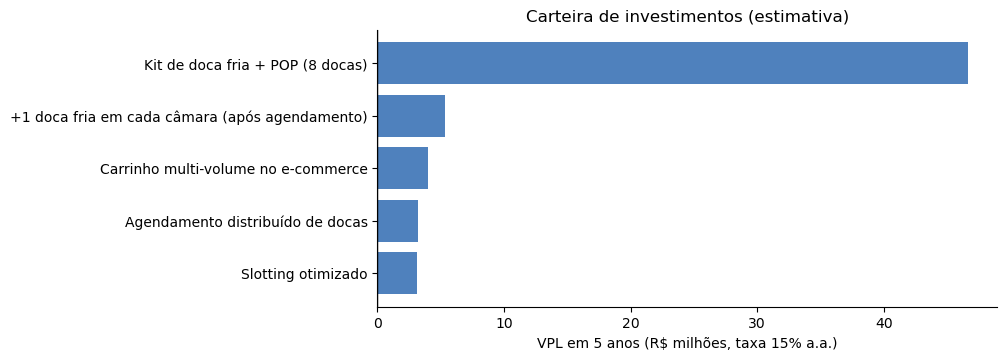

In [9]:
# Barras horizontais: VPL de cada projeto (ranking; o zero separa projetos que se pagam dos que não).
fig, ax = plt.subplots(figsize=(8, 3.6))
o = projetos.sort_values("vpl_5a")
ax.barh(o.projeto, o.vpl_5a / 1e6, color=np.where(o.vpl_5a > 0, "#4F81BD", "#C0504D"))
ax.axvline(0, color="black", lw=1); ax.set_xlabel("VPL em 5 anos (R$ milhões, taxa 15% a.a.)")
ax.set_title("Carteira de investimentos (estimativa)")
savefig(fig, "08b_vpl_projetos", out=PH8)

**Leitura:**
- **Kit de doca fria + POP** lidera de longe: a perda de frio é o maior custo do CD (08a). Mesmo com
  premissa pessimista (20% da perda crônica evitada), o VPL é muito alto. É a prioridade nº 1.
- **Carrinho do e-commerce** e **slotting** se pagam em semanas: o investimento é pequeno perto das
  horas de separação economizadas.
- **Agendamento** não tem CAPEX e reduz a espera em todas as zonas: é a primeira ação, imediata.
- A **doca fria extra** continua valendo **mesmo depois do agendamento** (−R$ 1,8 mi/ano em estadia;
  VPL positivo até com metade do custo de estadia premissado). O agendamento sozinho não resolve o
  frio: com 4 docas por câmara a fila é estrutural. Recomendação: agendar já e **orçar as 2 docas**,
  confirmando o custo de estadia com as transportadoras.
- TIRs de centenas de % só refletem CAPEX pequeno perto do benefício; o critério de decisão é o VPL.

In [10]:
for _, r in projetos.iterrows():
    register_saving(8, r.projeto + " (investimento)", "benefício anual (R$)", 0, round(r.beneficio_ano),
                    r.fonte_do_beneficio, f"VPL 5a {r.vpl_5a / 1e3:,.0f} mil; payback {r.payback_meses:.1f} meses; escala cheia",
                    r.beneficio_ano, round(r.capex))
log(NB, f"energia por zona; espera de carretas por simulação fev–mai/2026 x3; perda crônica de frio = ano-base "
        f"menos 06–18/jan/2026; VPL {ANOS} anos a {TAXA:.0%}; custo de hora paga (fator {FATOR_PAGO:.2f})")